# NN_L6_emb_training

**Training loss of word2vec (SGNS) by epoch and distribution of the GloVe co-occurrence counts, both on ECB speeches.**

Neural Networks and Deep Learning (NN), Lecture 6 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L6/NN_L6_emb_training/NN_L6_emb_training.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Left: SGNS loss per (centre, context) pair. Right: histogram of $\log_{10}X_{ij}$; GloVe gives weight 1 above $x_{max}=100$.

SGNS loss, epoch 1 = 2.622   [w2v.loss_first]
SGNS loss, last epoch = 2.223   [w2v.loss_last]
non-zero co-occurrence pairs = 3841517   [glove.nnz]


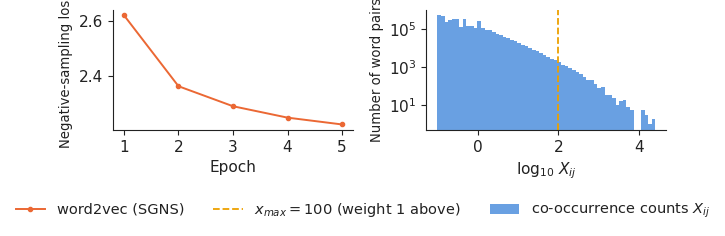

In [3]:
import json, urllib.request
_F = 'emb_training_results.json'
R = json.load(open(_F)) if os.path.isfile(_F) else json.load(urllib.request.urlopen(REPO + 'Quantlets/L6/NN_L6_emb_training/' + _F))
show('w2v.loss_first', 'SGNS loss, epoch 1', round(R['hist'][0], 3)); show('w2v.loss_last', 'SGNS loss, last epoch', round(R['hist'][-1], 3)); show('glove.nnz', 'non-zero co-occurrence pairs', R['nnz'])
fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.4)); axes[0].plot(np.arange(1, len(R['hist']) + 1), R['hist'], color=PAL['model'], marker='o', ms=3, label='word2vec (SGNS)')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Negative-sampling loss', fontsize=9.5); e = np.array(R['edges'])
axes[1].bar(e[:-1], R['counts'], width=np.diff(e), align='edge', color=PAL['data'], alpha=.7, label='co-occurrence counts $X_{ij}$'); axes[1].set_yscale('log')
axes[1].axvline(2, color=PAL['alt'], ls='--', lw=1.3, label='$x_{max}=100$ (weight 1 above)'); axes[1].set_xlabel('log$_{10}$ $X_{ij}$'); axes[1].set_ylabel('Number of word pairs', fontsize=9.5)
legend_bottom(fig, ncol=3); fig.tight_layout(rect=(0, .15, 1, 1))
fig.savefig('emb_training.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()